In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("data.csv", encoding="ISO-8859-1")

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
df = pd.read_csv("data.csv", encoding="ISO-8859-1")
df = df.dropna(subset=["CustomerID"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [5]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(5192)

In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(392692, 8)

In [10]:
df["TotalSpend"] = df["Quantity"] * df["UnitPrice"]

In [11]:
rfm = df.groupby("CustomerID").agg(
    LastDate=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalSpend", "sum"),
)

In [12]:
rfm["Recency"] = (df["InvoiceDate"].max() - rfm.pop("LastDate")).dt.days

In [13]:
X = StandardScaler().fit_transform(np.log1p(rfm))

In [14]:
rfm["KMeans"] = KMeans(n_clusters=4, random_state=42).fit_predict(X)
rfm["DBSCAN"] = DBSCAN(eps=0.8, min_samples=10).fit_predict(X)

In [15]:
pca = PCA(n_components=2).fit_transform(X)
tsne = TSNE(n_components=2, random_state=42).fit_transform(X)

Text(0.5, 1.0, 'K-Means Segments (PCA)')

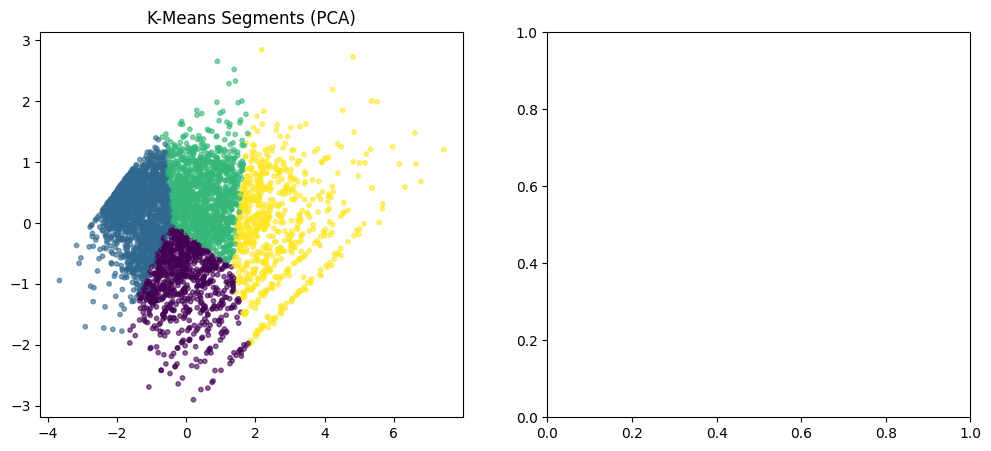

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(
    pca[:, 0], pca[:, 1], c=rfm["KMeans"], cmap="viridis", s=10, alpha=0.6
)
axes[0].set_title("K-Means Segments (PCA)")

In [17]:
axes[1].scatter(
    tsne[:, 0], tsne[:, 1], c=rfm["DBSCAN"], cmap="coolwarm", s=10, alpha=0.6
)
axes[1].set_title("DBSCAN Clusters (-1 = Outliers) (t-SNE)")

Text(0.5, 1.0, 'DBSCAN Clusters (-1 = Outliers) (t-SNE)')

In [18]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [19]:
print(
    rfm.groupby("KMeans")[["Recency", "Frequency", "Monetary"]]
    .mean()
    .round(1)
)

        Recency  Frequency  Monetary
KMeans                              
0          17.1        2.1     540.6
1         179.4        1.3     347.6
2          67.8        4.2    1830.5
3          10.4       14.0    8290.4


In [20]:
print(rfm["DBSCAN"].value_counts())

DBSCAN
 0    4306
-1      32
Name: count, dtype: int64
